In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [5]:
import tensorflow as tf
import torch

print("TensorFlow Version:", tf.__version__)
print("PyTorch Version:", torch.__version__)

print("GPU Devices:", tf.config.list_physical_devices('GPU'))
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

I0000 00:00:1794398885.195802     342 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow Version: 2.21.0
PyTorch Version: 2.11.0+cu130
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
CUDA Available: True
GPU Name: Tesla T4


In [6]:
!pip install -q transformers datasets evaluate accelerate scikit-learn

In [7]:
import transformers
import datasets
import evaluate
import accelerate
import sklearn

print("All libraries installed successfully!")
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)

All libraries installed successfully!
Transformers: 5.20.2
Datasets: 4.8.5


In [8]:
from datasets import load_dataset

dataset = load_dataset("fancyzhx/ag_news")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [9]:
print("Training samples:", len(dataset["train"]))
print("Testing samples:", len(dataset["test"]))

print("\nFirst training example:")
print(dataset["train"][0])

Training samples: 120000
Testing samples: 7600

First training example:
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [10]:
# Display first 5 news articles
for i in range(5):
    print(f"\nNews Article {i+1}")
    print("Text:", dataset["train"][i]["text"])
    print("Label:", dataset["train"][i]["label"])
    print("-" * 80)

# Display class names and label mapping
print("\nClass Names:")
print(dataset["train"].features["label"].names)


News Article 1
Text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
Label: 2
--------------------------------------------------------------------------------

News Article 2
Text: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.
Label: 2
--------------------------------------------------------------------------------

News Article 3
Text: Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums.
Label: 2
--------------------------------------------------------------------------------

News Article 4
Tex

In [11]:
# Check all four categories
class_names = dataset["train"].features["label"].names

for i, name in enumerate(class_names):
    print(f"Label {i}: {name}")

# Count samples in each category
from collections import Counter

label_counts = Counter(dataset["train"]["label"])

print("\nTraining Data Distribution:")
for label, count in sorted(label_counts.items()):
    print(f"{class_names[label]}: {count}")

Label 0: World
Label 1: Sports
Label 2: Business
Label 3: Sci/Tech

Training Data Distribution:
World: 30000
Sports: 30000
Business: 30000
Sci/Tech: 30000


In [12]:
from datasets import DatasetDict

# Split training data into train and validation
split_dataset = dataset["train"].train_test_split(
    test_size=0.10,
    seed=42,
    stratify_by_column="label"
)

# Create final dataset dictionary
dataset = DatasetDict({
    "train": split_dataset["train"],
    "validation": split_dataset["test"],
    "test": dataset["test"]
})

# Display dataset sizes
print("Training samples:", len(dataset["train"]))
print("Validation samples:", len(dataset["validation"]))
print("Testing samples:", len(dataset["test"]))

Training samples: 108000
Validation samples: 12000
Testing samples: 7600


In [13]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Vocabulary Size:", tokenizer.vocab_size)

Tokenizer loaded successfully!
Vocabulary Size: 30522


In [14]:
sample_text = dataset["train"][0]["text"]

tokens = tokenizer(
    sample_text,
    truncation=True,
    padding="max_length",
    max_length=128
)

print("Original Text:")
print(sample_text)

print("\nToken IDs:")
print(tokens["input_ids"][:20])

print("\nAttention Mask:")
print(tokens["attention_mask"][:20])

Original Text:
Three tied for lead at Southern Farm Bureau Classic John Senden carded a pair of eagles, Harrison Frazar shot a 31 on the front nine and Glen Day recorded seven birdies to finish Thursday #39;s first round of the 

Token IDs:
[101, 2093, 5079, 2005, 2599, 2012, 2670, 3888, 4879, 4438, 2198, 4604, 2368, 4003, 2098, 1037, 3940, 1997, 8125, 1010]

Attention Mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [15]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"],
    desc="Tokenizing dataset"
)

print(tokenized_dataset)

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 108000
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 12000
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7600
    })
})


In [16]:
print("Input IDs:")
print(tokenized_dataset["train"][0]["input_ids"][:20])

print("\nAttention Mask:")
print(tokenized_dataset["train"][0]["attention_mask"][:20])

print("\nLabel:")
print(tokenized_dataset["train"][0]["label"])

Input IDs:
[101, 2093, 5079, 2005, 2599, 2012, 2670, 3888, 4879, 4438, 2198, 4604, 2368, 4003, 2098, 1037, 3940, 1997, 8125, 1010]

Attention Mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Label:
1


In [17]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=4
)

print("Pretrained DistilBERT loaded successfully!")
print("\nModel Architecture:")
print(model)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Pretrained DistilBERT loaded successfully!

Model Architecture:
DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (

In [18]:
total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)

Total Parameters: 66956548
Trainable Parameters: 66956548


In [19]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Selected Device:", device)
print("GPU Name:", torch.cuda.get_device_name(0))
print("Model is on:", next(model.parameters()).device)

Selected Device: cuda
GPU Name: Tesla T4
Model is on: cuda:0


In [20]:
from torch.utils.data import DataLoader

# Remove unnecessary token_type_ids
for split in ["train", "validation", "test"]:
    tokenized_dataset[split] = tokenized_dataset[split].remove_columns(
        ["token_type_ids"]
    )

# Set PyTorch format
for split in ["train", "validation", "test"]:
    tokenized_dataset[split].set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "label"]
    )

print("Dataset converted to PyTorch format!")

Dataset converted to PyTorch format!


In [21]:
BATCH_SIZE = 32

train_loader = DataLoader(
    tokenized_dataset["train"],
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    tokenized_dataset["validation"],
    batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    tokenized_dataset["test"],
    batch_size=BATCH_SIZE
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Testing batches:", len(test_loader))

Training batches: 3375
Validation batches: 375
Testing batches: 238


In [22]:
batch = next(iter(train_loader))

print("Input IDs Shape:", batch["input_ids"].shape)
print("Attention Mask Shape:", batch["attention_mask"].shape)
print("Labels Shape:", batch["label"].shape)

Input IDs Shape: torch.Size([32, 128])
Attention Mask Shape: torch.Size([32, 128])
Labels Shape: torch.Size([32])


In [23]:
from torch.optim import AdamW

EPOCHS = 3
LEARNING_RATE = 2e-5

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

loss_function = torch.nn.CrossEntropyLoss()

print("Training Configuration")
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Optimizer: AdamW")
print("Loss Function: CrossEntropyLoss")

Training Configuration
Epochs: 3
Learning Rate: 2e-05
Optimizer: AdamW
Loss Function: CrossEntropyLoss


In [24]:
from transformers import get_linear_schedule_with_warmup

total_training_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_training_steps),
    num_training_steps=total_training_steps
)

print("Total Training Steps:", total_training_steps)
print("Warmup Steps:", int(0.1 * total_training_steps))
print("Scheduler initialized successfully!")

Total Training Steps: 10125
Warmup Steps: 1012
Scheduler initialized successfully!


In [25]:
import torch
from tqdm.auto import tqdm
import numpy as np

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0

print("Training environment ready!")

Training environment ready!


In [26]:
def train_one_epoch(model, train_loader, optimizer, scheduler, device):

    model.train()

    total_loss = 0
    correct_predictions = 0
    total_samples = 0

    progress_bar = tqdm(train_loader, desc="Training")

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        logits = outputs.logits

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        predictions = torch.argmax(logits, dim=1)

        correct_predictions += (predictions == labels).sum().item()
        total_samples += labels.size(0)

        progress_bar.set_postfix(loss=loss.item())

    avg_loss = total_loss / len(train_loader)
    accuracy = correct_predictions / total_samples

    return avg_loss, accuracy


def evaluate_model(model, data_loader, device):

    model.eval()

    total_loss = 0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():

        for batch in tqdm(data_loader, desc="Validation"):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_loss += outputs.loss.item()

            predictions = torch.argmax(outputs.logits, dim=1)

            correct_predictions += (predictions == labels).sum().item()
            total_samples += labels.size(0)

    avg_loss = total_loss / len(data_loader)
    accuracy = correct_predictions / total_samples

    return avg_loss, accuracy


print("Training and evaluation functions defined successfully!")

Training and evaluation functions defined successfully!


In [27]:
EPOCHS = 3
LEARNING_RATE = 2e-5

print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)

Epochs: 3
Learning Rate: 2e-05


In [28]:
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

total_training_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_training_steps),
    num_training_steps=total_training_steps
)

print("Optimizer and Scheduler ready!")
print("Total Training Steps:", total_training_steps)

Optimizer and Scheduler ready!
Total Training Steps: 10125


In [29]:
import time

for epoch in range(EPOCHS):

    print(f"\n{'='*50}")
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"{'='*50}")

    start_time = time.time()

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, optimizer, scheduler, device
    )

    val_loss, val_accuracy = evaluate_model(
        model, validation_loader, device
    )

    epoch_time = time.time() - start_time

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(f"\nTraining Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.4f}")

    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")

    print(f"Epoch Time: {epoch_time:.2f} seconds")

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "best_distilbert_agnews.pth"
        )

        print("Best model saved!")

print("\nTraining completed!")
print("Best Validation Accuracy:", best_val_accuracy)


Epoch 1/3


Training:   0%|          | 0/3375 [00:00<?, ?it/s]

Validation:   0%|          | 0/375 [00:00<?, ?it/s]


Training Loss: 0.3059
Training Accuracy: 0.8973
Validation Loss: 0.1847
Validation Accuracy: 0.9387
Epoch Time: 1126.13 seconds
Best model saved!

Epoch 2/3


Training:   0%|          | 0/3375 [00:00<?, ?it/s]

Validation:   0%|          | 0/375 [00:00<?, ?it/s]


Training Loss: 0.1426
Training Accuracy: 0.9528
Validation Loss: 0.1764
Validation Accuracy: 0.9443
Epoch Time: 1129.16 seconds
Best model saved!

Epoch 3/3


Training:   0%|          | 0/3375 [00:00<?, ?it/s]

Validation:   0%|          | 0/375 [00:00<?, ?it/s]


Training Loss: 0.0984
Training Accuracy: 0.9691
Validation Loss: 0.1870
Validation Accuracy: 0.9455
Epoch Time: 1129.11 seconds
Best model saved!

Training completed!
Best Validation Accuracy: 0.9455


In [30]:
# Load the best saved model

model.load_state_dict(
    torch.load("best_distilbert_agnews.pth", map_location=device)
)

model.to(device)

print("Best model loaded successfully!")
print("Best Validation Accuracy:", best_val_accuracy)

Best model loaded successfully!
Best Validation Accuracy: 0.9455


In [31]:
# Evaluate the model on the test dataset

test_loss, test_accuracy = evaluate_model(
    model,
    test_loader,
    device
)

print("\nFinal Test Results")
print("========================")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

Validation:   0%|          | 0/238 [00:00<?, ?it/s]


Final Test Results
Test Loss: 0.1821
Test Accuracy: 0.9468
Test Accuracy (%): 94.68%


In [32]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for batch in tqdm(test_loader, desc="Generating Predictions"):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

class_names = ["World", "Sports", "Business", "Sci/Tech"]

print("\nClassification Report")
print("==============================")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
))

print("\nConfusion Matrix")
print("==============================")

cm = confusion_matrix(all_labels, all_predictions)

print(cm)

Generating Predictions:   0%|          | 0/238 [00:00<?, ?it/s]


Classification Report
              precision    recall  f1-score   support

       World       0.96      0.96      0.96      1900
      Sports       0.99      0.99      0.99      1900
    Business       0.93      0.91      0.92      1900
    Sci/Tech       0.91      0.93      0.92      1900

    accuracy                           0.95      7600
   macro avg       0.95      0.95      0.95      7600
weighted avg       0.95      0.95      0.95      7600


Confusion Matrix
[[1816   11   42   31]
 [  11 1874    8    7]
 [  33    5 1731  131]
 [  27    9   89 1775]]


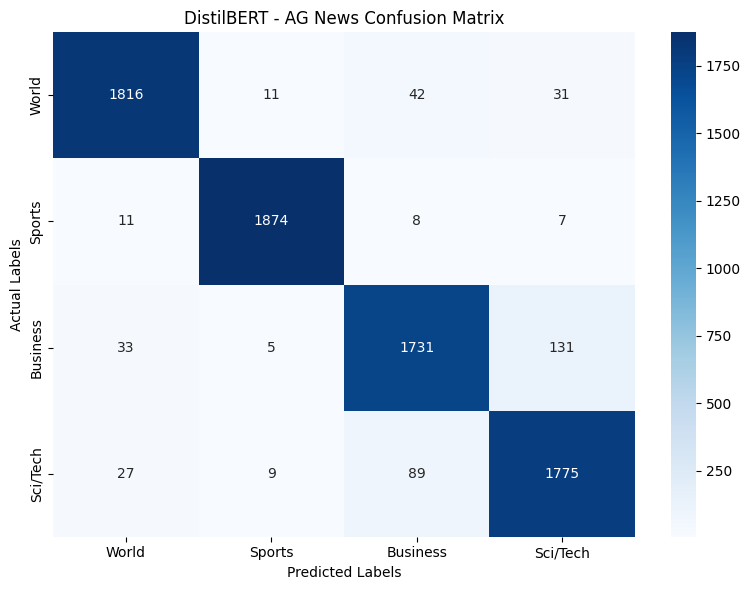

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("DistilBERT - AG News Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.tight_layout()
plt.show()